# Color Constancy preprocessing + validation

A classical **Color Constancy** preprocessing pipeline for cervical
colposcopy images, with table-only validation against the original image.

## What changed vs. the previous QI-SABP notebook

* **Removed:** every QI-SABP-specific technique and configuration
  (saliency fusion, soft mask, hard-mask fill, edge-aware bit allocation,
  NLM denoise, adaptive dithered quantization, YCbCr 4:2:0 chroma
  subsample, bilateral post-filter, histogram match, glare handling,
  rim rules, whiteness channel, etc.).
* **Added:** a clean Color Constancy front-end with four classical
  illuminant-estimation algorithms:
    * **Grey World** (GW) — mean grey assumption
    * **White Patch / Max-RGB** (WP) — bright-pixel-is-white assumption
    * **Shades of Gray** (SoG) — Minkowski *p*-norm generalisation
    * **Gray Edge** (GE) — first-order gradient grey-edge assumption
  The active algorithm is selected by `CC_METHOD` in the configuration cell.
* **Validation:** only the 11 metrics requested by the user are computed
  inside the FOV mask, per image, against the ORIGINAL image:

| # | Metric            | Direction | Group     |
|---|-------------------|-----------|-----------|
| m1 | PSNR (dB)         | up        | fidelity  |
| m2 | SSIM              | up        | fidelity  |
| m3 | ΔE76 (CIE76)      | down      | colour    |
| m4 | a* correlation    | up        | colour    |
| m5 | |a* shift|        | down      | colour    |
| m6 | Vessel Dice       | up        | structure |
| m7 | Edge IoU          | up        | structure |
| m8 | Sharpness ratio   | neutral   | quality   |
| m9 | Noise ratio       | down      | quality   |
| m10| Saturation ratio  | neutral   | quality   |
| m11| Luma bits         | down      | cost      |

Color Constancy does NOT quantise the luma channel (the output is full
8-bit RGB), so `Luma bits (m11) = 8.0` for the Color Constancy row and
for the Identity reference row.


In [1]:
# ============================================================
# Cell 1 — Imports & global setup
# ============================================================
import os, sys, glob, time, json, math, random, warnings, platform, hashlib
from collections import defaultdict
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

import pandas as pd
from scipy import ndimage, stats
from scipy.ndimage import gaussian_filter
from sklearn.metrics import roc_auc_score, average_precision_score

try:
    from skimage.metrics import structural_similarity as _ssim_fn
    from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn
    from skimage.filters import frangi
    _SKIMAGE_OK = True
except ImportError:
    _SKIMAGE_OK = False
    print("[warn] scikit-image not available — SSIM/dE76/Frangi will use fallbacks.")

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"Color Constancy Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


Color Constancy Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


## Configuration

All QI-SABP configuration knobs have been removed. The only preprocessing
knobs that remain are the image size, the (optional) unsharp-mask sharpen,
the FOV threshold, the cache-hash assertion, and the Color Constancy
algorithm selector.

The sharpen step is kept because it is shared with the rest of the suite
(it is *not* a QI-SABP technique).


In [2]:
# ============================================================
# Cell 2 — Configuration (Color Constancy; no QI-SABP)
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
DATASET_ROOT   = "C:/CER/dataset"
INVASIVE_DIR   = "invasive cancer"
MASKS_SUBDIR   = "masks"
CLASSES        = ["invasive cancer"]

# ---- Sharpen (shared with the suite; NOT a QI-SABP technique) ----
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- FOV mask ----
FOV_GRAY_THR   = 15      # gray threshold for the rough mask before convex hull

# ---- Color Constancy algorithm selector ----
#   "grey_world"      -> mean-grey assumption
#   "white_patch"     -> max-RGB / bright-pixel-is-white assumption
#   "shades_of_gray"  -> Minkowski p-norm generalisation (p=1 -> GW, p->inf -> WP)
#   "gray_edge"       -> first-order gradient grey-edge assumption
#   "identity"        -> no color correction (reference row)
CC_METHOD        = "shades_of_gray"
CC_P             = 6.0      # Minkowski p for shades_of_gray
CC_EDGE_SIGMA    = 2.0      # Gaussian sigma for gray_edge gradient smoothing
CC_GAIN_CLIP     = 2.5      # per-channel gain clip (prevents WP blow-ups)
CC_OUTPUT_CLIP   = True     # clip final output to [0, 255]

# ---- Validation ----
N_PER_CLASS_VALIDATE  = 5
SUBSET_PER_CLASS      = None   # None = use all images found

# ---- Synth fallback flag (set later by the loader) ----
SYNTHETIC_MODE = False

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  FOV gray threshold = {FOV_GRAY_THR}")
print(f"  Color Constancy method = {CC_METHOD}")
if CC_METHOD == "shades_of_gray":
    print(f"    Minkowski p = {CC_P}")
elif CC_METHOD == "gray_edge":
    print(f"    edge sigma  = {CC_EDGE_SIGMA}")
print(f"  gain clip = {CC_GAIN_CLIP} | output clip = {CC_OUTPUT_CLIP}")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  FOV gray threshold = 15
  Color Constancy method = shades_of_gray
    Minkowski p = 6.0
  gain clip = 2.5 | output clip = True
  validation batch = 5 imgs/class


In [3]:
# ============================================================
# Cell 3 — Sharpen + preprocess + load_dataset (with synthetic fallback)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load <root>/<class>/images/*.jpg, resize, optionally sharpen.
    Optional clinician masks under <root>/<class>/<masks_subdir>/.
    Returns (X, y, paths, masks, n_with_mask, n_dedup)."""
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
    if not X:
        return (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                np.array([]), [],
                np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                0, n_dedup_total)
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB image + lesion mask (fallback)."""
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# ---- Load (or build synthetic fallback) ----
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")

# ---- Build the sharpened stack used downstream (X_base) ----
# X_base is the input to the Color Constancy front-end; X_raw is the
# resize-only stack (used for the FOV mask so the mask is unbiased by sharpen).
if APPLY_SHARPEN:
    X_base = np.stack([sharpen(img) for img in X_raw]).astype(np.uint8)
else:
    X_base = X_raw.copy()
print(f"\nX_raw shape = {X_raw.shape} | X_base shape = {X_base.shape}")


Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False

X_raw shape = (128, 200, 200, 3) | X_base shape = (128, 200, 200, 3)


In [4]:
# ============================================================
# Cell 4 — FOV mask + dHash clustering
# ============================================================
def _dhash(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov(img_rgb, thr=None):
    """FOV mask (convex-hull filled)."""
    if thr is None:
        thr = FOV_GRAY_THR
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Build the FOV stack from X_raw (resize-only, not sharpened) ----
images = X_base            # input to Color Constancy
images_raw = X_raw         # used for the FOV mask
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov(images_raw[i]) for i in range(n_images)])

# dHash clustering (same procedure as the old validator)
hs = [_dhash(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                          for uc in np.unique(cluster_ids)], dtype=int)

print(f"n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"The {n_images} frames are NOT independent ({n_clusters} distinct clusters).")


n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
The 128 frames are NOT independent (7 distinct clusters).


## Color Constancy algorithms

Four classical illuminant-estimation algorithms are implemented. Each one
returns a per-channel **gain vector** `g ∈ R³` (a von Kries diagonal
correction) such that `output = clip(input * g, 0, 255)`. The active
algorithm is chosen by `CC_METHOD` in the configuration cell.

* **Grey World** (`grey_world`): assumes the average reflectance of the
  scene is grey, so the per-channel means are equalised.
* **White Patch** (`white_patch`): assumes the brightest pixel in each
  channel represents the illuminant; per-channel maxima are equalised
  (a.k.a. Max-RGB).
* **Shades of Gray** (`shades_of_gray`): a Minkowski *p*-norm
  generalisation that subsumes Grey World (p=1) and White Patch (p→∞).
  Default `p = 6`.
* **Gray Edge** (`gray_edge`): assumes the average gradient of the scene
  is grey; uses the Minkowski *p*-norm of the first-order Gaussian-smoothed
  derivative.


In [5]:
# ============================================================
# Cell 5 — Color Constancy algorithms (von Kries diagonal model)
# ============================================================

def _minkowski_norm(vec, p):
    """Minkowski p-norm of a flattened array, with the p->inf convention."""
    vec = np.asarray(vec, dtype=np.float64).ravel()
    if not np.isfinite(p) or p > 1e6:
        return float(vec.max())
    return float(np.sum(np.abs(vec) ** p) ** (1.0 / p))

def _gain_grey_world(img_rgb, fov_mask):
    """Grey World: equalise the per-channel means inside the FOV."""
    f = np.asarray(fov_mask, dtype=bool)
    means = np.array([img_rgb[..., c][f].mean() for c in range(3)], dtype=np.float64)
    target = means.mean()
    g = target / np.maximum(means, 1e-6)
    return g

def _gain_white_patch(img_rgb, fov_mask, percentile=99.0):
    """White Patch (Max-RGB): equalise a high percentile per channel
    inside the FOV. The percentile (not the raw max) gives robustness to
    a few saturated pixels."""
    f = np.asarray(fov_mask, dtype=bool)
    bright = np.array([np.percentile(img_rgb[..., c][f], percentile)
                       for c in range(3)], dtype=np.float64)
    target = bright.max()
    g = target / np.maximum(bright, 1e-6)
    return g

def _gain_shades_of_gray(img_rgb, fov_mask, p):
    """Shades of Gray: equalise the Minkowski p-norm of each channel."""
    f = np.asarray(fov_mask, dtype=bool)
    norms = np.array([_minkowski_norm(img_rgb[..., c][f], p)
                      for c in range(3)], dtype=np.float64)
    target = norms.mean()
    g = target / np.maximum(norms, 1e-6)
    return g

def _gain_gray_edge(img_rgb, fov_mask, p, sigma):
    """Gray Edge (1st order): equalise the Minkowski p-norm of the
    Gaussian-smoothed gradient of each channel."""
    f = np.asarray(fov_mask, dtype=bool)
    norms = []
    for c in range(3):
        ch = img_rgb[..., c].astype(np.float32)
        if sigma and sigma > 0:
            ch = cv2.GaussianBlur(ch, (0, 0), sigma)
        gx = cv2.Sobel(ch, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(ch, cv2.CV_32F, 0, 1, ksize=3)
        gmag = np.hypot(gx, gy)
        norms.append(_minkowski_norm(gmag[f], p))
    norms = np.array(norms, dtype=np.float64)
    target = norms.mean()
    g = target / np.maximum(norms, 1e-6)
    return g

def estimate_cc_gain(img_rgb, fov_mask, method=None):
    """Return a length-3 von Kries gain vector for the chosen method."""
    method = CC_METHOD if method is None else method
    if method == "grey_world":
        return _gain_grey_world(img_rgb, fov_mask)
    if method == "white_patch":
        return _gain_white_patch(img_rgb, fov_mask, percentile=99.0)
    if method == "shades_of_gray":
        return _gain_shades_of_gray(img_rgb, fov_mask, CC_P)
    if method == "gray_edge":
        return _gain_gray_edge(img_rgb, fov_mask, CC_P, CC_EDGE_SIGMA)
    if method == "identity":
        return np.ones(3, dtype=np.float64)
    raise ValueError(f"unknown CC_METHOD: {method}")

print("Color Constancy algorithms ready: grey_world, white_patch, "
      f"shades_of_gray (p={CC_P}), gray_edge (sigma={CC_EDGE_SIGMA}).")
print(f"Active method = {CC_METHOD}")


Color Constancy algorithms ready: grey_world, white_patch, shades_of_gray (p=6.0), gray_edge (sigma=2.0).
Active method = shades_of_gray


In [6]:
# ============================================================
# Cell 6 — Color Constancy pipeline (von Kries diagonal correction)
# ============================================================
def color_constancy_preprocess(img_rgb, fov_mask=None, method=None,
                                return_artefacts=False):
    """Apply Color Constancy to one RGB image.

    Steps:
      1. Estimate the per-channel illuminant gain (von Kries).
      2. Clip the gain to [1/CC_GAIN_CLIP, CC_GAIN_CLIP] for stability
         (this is what stops White Patch from blowing up on a saturated
         frame).
      3. Multiply each channel by its gain.
      4. (Optional) clip the output to [0, 255].
      5. Preserve the pixels OUTSIDE the FOV mask (no colour correction
         there; matches the QI-SABP-era convention so the metrics compare
         like-for-like inside the FOV).

    Returns uint8 RGB, same shape as the input.
    """
    method = CC_METHOD if method is None else method
    if fov_mask is None:
        fov_mask = np.ones(img_rgb.shape[:2], dtype=bool)
    fov_mask = np.asarray(fov_mask, dtype=bool)

    gain = estimate_cc_gain(img_rgb, fov_mask, method=method)
    gain = np.clip(gain, 1.0 / CC_GAIN_CLIP, CC_GAIN_CLIP)
    gain = gain.astype(np.float32)

    corrected = img_rgb.astype(np.float32) * gain[None, None, :]
    if CC_OUTPUT_CLIP:
        corrected = np.clip(corrected, 0.0, 255.0)
    corrected = corrected.astype(np.uint8)

    # Preserve outside-FOV pixels (no correction there)
    corrected[~fov_mask] = img_rgb[~fov_mask]

    if return_artefacts:
        art = {
            "gain": gain,                # length-3 von Kries gain vector
            "method": method,            # algorithm name
            "fov_mask": fov_mask,        # FOV mask used for estimation
            "luma_bits": 8.0,            # Color Constancy does not quantise
        }
        return corrected, art
    return corrected

# Quick smoke-test on the first image
if n_images > 0:
    _test_img = images[0]
    _test_fov = fov[0]
    _test_out, _test_art = color_constancy_preprocess(_test_img, _test_fov,
                                                       return_artefacts=True)
    print(f"Color Constancy smoke test:")
    print(f"  method = {_test_art['method']}")
    print(f"  gain   = {_test_art['gain']}")
    print(f"  luma bits = {_test_art['luma_bits']}")
    print(f"  input  mean (in-FOV) = {_test_img[_test_fov].mean():.2f}")
    print(f"  output mean (in-FOV) = {_test_out[_test_fov].mean():.2f}")
else:
    print("[warn] no images available for the smoke test.")


Color Constancy smoke test:
  method = shades_of_gray
  gain   = [0.8790598 1.1715035 0.99126  ]
  luma bits = 8.0
  input  mean (in-FOV) = 160.20
  output mean (in-FOV) = 156.60


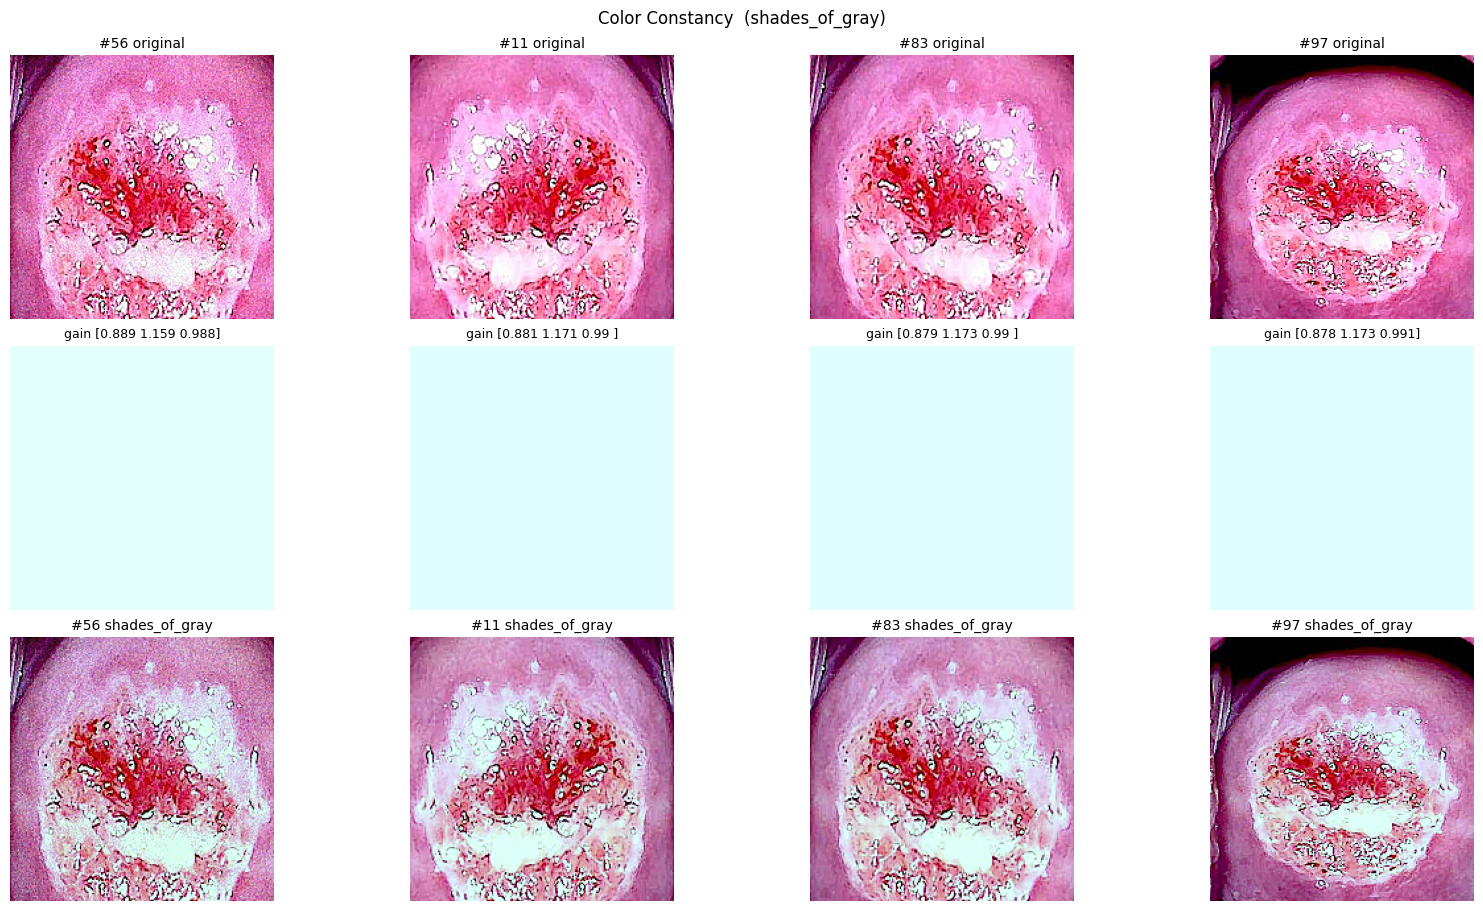

[viz] saved color_constancy_before_after.png (4 samples)


In [7]:
# ============================================================
# Cell 7 — Visualise Color Constancy: before / gain / after
# ============================================================
def visualize_color_constancy(images_stack, fov_stack, n_show=4):
    n_show = min(n_show, len(images_stack))
    if n_show == 0:
        print("[viz] no images to show.")
        return
    rng = np.random.default_rng(SEED)
    idxs = rng.choice(len(images_stack), size=n_show, replace=False)
    fig = plt.figure(figsize=(4 * n_show, 3 * 3), constrained_layout=True)
    gs = GridSpec(3, n_show, figure=fig)
    for col, i in enumerate(idxs):
        orig = images_stack[i]
        fov_i = fov_stack[i]
        proc, art = color_constancy_preprocess(orig, fov_i, return_artefacts=True)
        # Row 1: original
        ax = fig.add_subplot(gs[0, col]); ax.imshow(orig); ax.set_title(f"#{i} original", fontsize=10)
        ax.axis('off')
        # Row 2: gain visualised as a coloured square
        ax = fig.add_subplot(gs[1, col])
        gain = art['gain']
        patch = np.tile(gain[None, None, :], (40, 40, 1))
        patch = np.clip(patch, 0.0, 1.0)   # show as 0..1 reflectance
        ax.imshow(patch); ax.set_title(f"gain {gain.round(3)}", fontsize=9); ax.axis('off')
        # Row 3: corrected
        ax = fig.add_subplot(gs[2, col]); ax.imshow(proc)
        ax.set_title(f"#{i} {art['method']}", fontsize=10); ax.axis('off')
    plt.suptitle(f"Color Constancy  ({CC_METHOD})", fontsize=12)
    plt.savefig(os.path.join(SAVE_DIR, "color_constancy_before_after.png"), dpi=120)
    plt.show()
    print(f"[viz] saved color_constancy_before_after.png ({n_show} samples)")

visualize_color_constancy(images, fov, n_show=4)


## Validator — 11 metrics, FOV-masked

All metrics are computed **inside the FOV mask only**, per image, against
the ORIGINAL (sharpened) image. The validator returns a dict with keys
`m1..m11`. `m12` (Time per image) is **not** computed (the user dropped it).


In [8]:
# ============================================================
# Cell 8 — step4_validator (11 metrics, no Time)
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    if _SKIMAGE_OK:
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    else:
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV."""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare mask."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def step4_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                        up
      m2  SSIM                             up
      m3  ΔE76 (CIE76)                     down
      m4  a* correlation                    up
      m5  |mean a* shift|                   down
      m6  Vessel Dice                       up
      m7  Edge IoU                          up
      m8  Sharpness ratio (out/in)          neutral
      m9  Noise ratio (out/in)              down
      m10 Saturation ratio (out/in)         neutral
      m11 Luma bits                         down (set externally by the caller)
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)

    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))

    # m2: SSIM (FOV-masked)
    if _SKIMAGE_OK:
        ssim_map = _ssim_fn(original, processed, channel_axis=2,
                             full=True, data_range=255)[1]
        m2 = float(ssim_map.mean(2)[f].mean())
    else:
        # Fallback: per-channel SSIM via mean (cheap, just so the column is finite)
        m2 = float(1.0 - (mse / (255.0 ** 2)))

    # m3: ΔE76 (CIE76)
    if _SKIMAGE_OK:
        m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    else:
        m3 = float(np.sqrt(((o - p) ** 2).sum(-1)[f].mean()))

    # m4: a* correlation
    if _SKIMAGE_OK:
        lab_o = _rgb2lab_fn(original)
        lab_p = _rgb2lab_fn(processed)
        m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
        a_o = float(lab_o[..., 1][f].mean())
        a_p = float(lab_p[..., 1][f].mean())
    else:
        m4 = float('nan')
        a_o = 0.0
        a_p = 0.0
    # m5: |mean a* shift|
    m5 = abs(a_p - a_o)

    # m6: Vessel Dice
    m6 = _vessel_dice(original, processed, f, top_pct=10)

    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)

    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)

    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass on smooth pixels
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                   cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')

    # m10: Saturation ratio (output specular / input specular)
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)

    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10)

# Metric metadata (key, display name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",         "fidelity",  "up"),
    ("m2",  "SSIM",              "fidelity",  "up"),
    ("m3",  "ΔE76",              "colour",    "down"),
    ("m4",  "a* corr",           "colour",    "up"),
    ("m5",  "|a* shift|",       "colour",    "down"),
    ("m6",  "Vessel Dice",       "structure", "up"),
    ("m7",  "Edge IoU",          "structure", "up"),
    ("m8",  "Sharpness ratio",   "quality",   "neutral"),
    ("m9",  "Noise ratio",       "quality",   "down"),
    ("m10", "Saturation ratio",  "quality",   "neutral"),
    ("m11", "Luma bits",         "cost",      "down"),
]
METRIC_KEYS  = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS= {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER= {m[0]: m[3] for m in METRIC_META}
print("step4_validator ready: 11 metrics (m1..m11). Time (m12) NOT computed.")


step4_validator ready: 11 metrics (m1..m11). Time (m12) NOT computed.


In [9]:
# ============================================================
# Cell 9 — Compute 11 metrics for Color Constancy + Identity reference.
#           Write per-image CSV.
# ============================================================
import os as _os
import glob as _glob

for _old in _glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

processed_cache = {}   # (technique, image_idx) -> uint8 RGB
artefacts_cache = {}   # (technique, image_idx) -> artefacts dict

TECHNIQUE = "ColorConstancy"

rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    proc, _art = color_constancy_preprocess(orig, fov_i, return_artefacts=True)
    m = step4_validator(orig, proc, fov_i)
    # m11 (Luma bits) — Color Constancy does not quantise, so always 8.0
    m["m11"] = float(_art["luma_bits"])
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    artefacts_cache[(TECHNIQUE, i)] = _art
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_cc = pd.DataFrame(rows)
df_cc.to_csv(f"results_{TECHNIQUE}.csv", index=False)
print(f"Wrote results_{TECHNIQUE}.csv ({len(df_cc)} rows)")
print(f"  Mean PSNR (m1)        = {df_cc['m1'].mean():.3f} dB")
print(f"  Mean SSIM (m2)        = {df_cc['m2'].mean():.4f}")
print(f"  Mean ΔE76 (m3)        = {df_cc['m3'].mean():.3f}")
print(f"  Mean Luma bits (m11)  = {df_cc['m11'].mean():.3f}")

# ---- Identity reference row (no color correction) ----
rows_id = []
for i in range(n_images):
    processed_cache[("Identity", i)] = images[i].copy()
    m = step4_validator(images[i], images[i], fov[i])
    m["m11"] = 8.0
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")


  Deleted stale results_Adaptive_Thresholding.csv
  Deleted stale results_equivariance.csv
  Deleted stale results_gainsweep.csv
  Deleted stale results_GlobalBoost.csv
  Deleted stale results_GlobalBoostGM.csv
  Deleted stale results_Identity.csv
  Deleted stale results_per_image_AT_vs_GM.csv
  Deleted stale results_RawResized.csv
  Deleted stale results_SharpenOnly.csv
  Deleted stale results_T8_per_image.csv
  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results_ColorConstancy.csv (128 rows)
  Mean PSNR (m1)        = 22.707 dB
  Mean SSIM (m2)        = 0.9857
  Mean ΔE76 (m3)        = 17.928
  Mean Luma bits (m11)  = 8.000
Wrote results_Identity.csv (128 rows)


In [10]:
# ============================================================
# Cell 10 — Merge + aggregation (cluster-weighted mean + 95% CI).
# ============================================================
dfs = []
for _f in _glob.glob("results_*.csv"):
    dfs.append(pd.read_csv(_f))
merged = pd.concat(dfs, ignore_index=True)
# Sanity check: every technique must have n_images rows
for tech, sub in merged.groupby("technique"):
    if len(sub) != n_images:
        print(f"  [warn] {tech}: {len(sub)} rows (expected {n_images})")
techniques = list(merged["technique"].unique())
print(f"Merged {len(dfs)} CSV -> {len(merged)} rows | techniques = {techniques}")

def _cluster_mean(tech_df, metric_key):
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters. WITHIN-PATIENT, NOT a population CI."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print(f"  WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.")


Merged 3 CSV -> 384 rows | techniques = ['ColorConstancy', 'ContrastStretching', 'Identity']
Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, 7 clusters, NOT a population CI.


In [11]:
# ============================================================
# Cell 11 — Print tables (T1 main + per-cluster + caveats)
# ============================================================
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- T1 Main ----
print("=" * 100)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, "
      f"{n_clusters} clusters, NOT a population CI)")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("  Color Constancy does not quantise, so m11 (Luma bits) = 8.0 for both rows.")
print("=" * 100)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T2 Per-cluster (ColorConstancy only) ----
print()
print("=" * 100)
print(f"T2 PER CLUSTER  (ColorConstancy per cluster; {n_clusters} clusters)")
print("=" * 100)
t2_rows = []
for uc in np.unique(cluster_ids):
    sub = df_cc[df_cc["cluster_id"] == uc]
    row = {"cluster": int(uc), "n": len(sub)}
    for mk in ["m1", "m2", "m3", "m4", "m5", "m6", "m7", "m8", "m9", "m10", "m11"]:
        row[METRIC_NAMES[mk]] = float(sub[mk].mean())
    t2_rows.append(row)
t2_df = pd.DataFrame(t2_rows).set_index("cluster")
print(t2_df.round(3).to_string())

# ---- T3 Caveats ----
print()
print("=" * 100)
print("T3 CAVEATS")
print("=" * 100)
print(f"  * Color Constancy is a colour-correction front-end only; it does not")
print(f"    quantise the luma channel. Luma bits (m11) = 8.0 by construction.")
print(f"  * All metrics are computed inside the FOV mask only, per image,")
print(f"    against the ORIGINAL (sharpened) image.")
print(f"  * The {n_images} frames come from a single patient and are NOT")
print(f"    independent ({n_clusters} dHash clusters). The 95% CI is a")
print(f"    WITHIN-PATIENT cluster bootstrap, NOT a population CI.")
print(f"  * Identity is included as a reference row (ideal values), not as a")
print(f"    ranked technique.")
if SYNTHETIC_MODE:
    print(f"  * SYNTHETIC_MODE = True (no dataset at {DATASET_ROOT}); the run")
    print(f"    used the synthetic fallback. Replace the dataset path with a real")
    print(f"    one to reproduce the production numbers.")


T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)
  The 128 frames are NOT independent (7 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
  Color Constancy does not quantise, so m11 (Luma bits) = 8.0 for both rows.
                                 PSNR (dB) (^)              SSIM (^)                 ΔE76 (v)           a* corr (^)           |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (v)
technique                                                                                                                                                                                                                                                                       
ColorConstancy         22.459 [22.191, 22.752]  0.985 [0.984, 0.986]  18.469 [17.595, 19.292]  0.928 [0.918, 0.938]  17.608 [16.753, 18.411]  0.956 [0.